# Accuracy vs Cost Tradeoff — xRouteBench

By default, all results use the **same fixed 200-query held-out evaluation
sample** from
`llmrouter_generic`. Candidate-model points are static policies (always use
one model); router and oracle points are query-dependent policies.

- **Chart 1 — Model vs Accuracy:** average task score per candidate.
- **Chart 2 — Model vs Cost:** average per-query dollar cost per candidate
  (from `llm_candidates` pricing × token usage).
- **Chart 3 — Cost vs Accuracy scatter (business case):** shows where the
  "cheap and good" models sit — the Pareto frontier a router exploits.

Reported cost is candidate-generation cost from xRouteBench pricing and
recorded token usage. It excludes router inference, infrastructure overhead,
and latency. Mean task score is query-micro-averaged; the table also reports
a task-macro average so the benchmark task mix is visible.

In [1]:
import sys
from pathlib import Path

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()),
    Path.cwd(),
)
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import pandas as pd

from router.eval_router import router_vs_gt, sample_split
from router.metrics import load_splits

# Freeze one evaluation population for every static model and every router run.
# Use `full_test` for the final 9B-vs-27B comparison (preferably evaluated on H200).
EVAL_SCOPE = "pilot_200"  # one of: pilot_200, full_test
assert EVAL_SCOPE in {"pilot_200", "full_test"}
eval_records = (
    sample_split("test") if EVAL_SCOPE == "pilot_200"
    else load_splits(split="test")
)
candidate_rows = [
    {
        "model_name": candidate["model"],
        "task": record["task"],
        "accuracy": candidate["perf"],
        "mean_cost": candidate["cost_usd"],
    }
    for record in eval_records
    for candidate in record["candidates"]
]
candidate_eval = pd.DataFrame(candidate_rows)
agg = (
    candidate_eval.groupby("model_name", as_index=False)
    .agg(accuracy=("accuracy", "mean"), mean_cost=("mean_cost", "mean"), rows=("accuracy", "size"))
)
task_macro = (
    candidate_eval.groupby(["model_name", "task"], as_index=False)["accuracy"].mean()
    .groupby("model_name", as_index=False)["accuracy"].mean()
    .rename(columns={"accuracy": "task_macro_score"})
)
agg = agg.merge(task_macro, on="model_name", validate="one_to_one")

def pareto_frontier(frame):
    ordered = frame.sort_values(["mean_cost", "accuracy"], ascending=[True, False]).reset_index(drop=True)
    prior_best = ordered["accuracy"].cummax().shift(fill_value=float("-inf"))
    return ordered.loc[ordered["accuracy"].gt(prior_best)].reset_index(drop=True)

pareto = pareto_frontier(agg)
if EVAL_SCOPE == "pilot_200":
    assert len(eval_records) == 200
assert agg["rows"].eq(len(eval_records)).all()
print(f"evaluation_queries={len(eval_records)}  candidates={len(agg)}")
print(agg.sort_values("accuracy", ascending=False).to_string(index=False))
print("\nStatic-model Pareto frontier:")
print(pareto[["model_name", "accuracy", "mean_cost"]].to_string(index=False))


/home/mr/Desktop/Fireworks/.route_f/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


evaluation_queries=200  candidates=18
                  model_name  accuracy  mean_cost  rows  task_macro_score
            cogito-v2-1-671b  0.811290   0.000482   200          0.717555
                gpt-oss-120b  0.756250   0.000047   200          0.687922
 qwen3-next-80b-a3b-instruct  0.726600   0.000470   200          0.583858
            llama-4-maverick  0.717105   0.000339   200          0.672039
llama-3.3-70b-instruct-turbo  0.711905   0.000290   200          0.665443
               deepseek-v3.1  0.711667   0.000315   200          0.665189
                 gpt-oss-20b  0.711500   0.000014   200          0.657956
         llama3-70b-instruct  0.692222   0.000167   200          0.631730
            qwen3-coder-next  0.681818   0.000377   200          0.646129
mistral-small-3-24b-instruct  0.667222   0.000065   200          0.645432
               gemma-2-9b-it  0.657222   0.000024   200          0.547093
 mixtral-8x22b-instruct-v0.1  0.641600   0.000353   200          0.619017


## Chart 1 — Model vs Accuracy

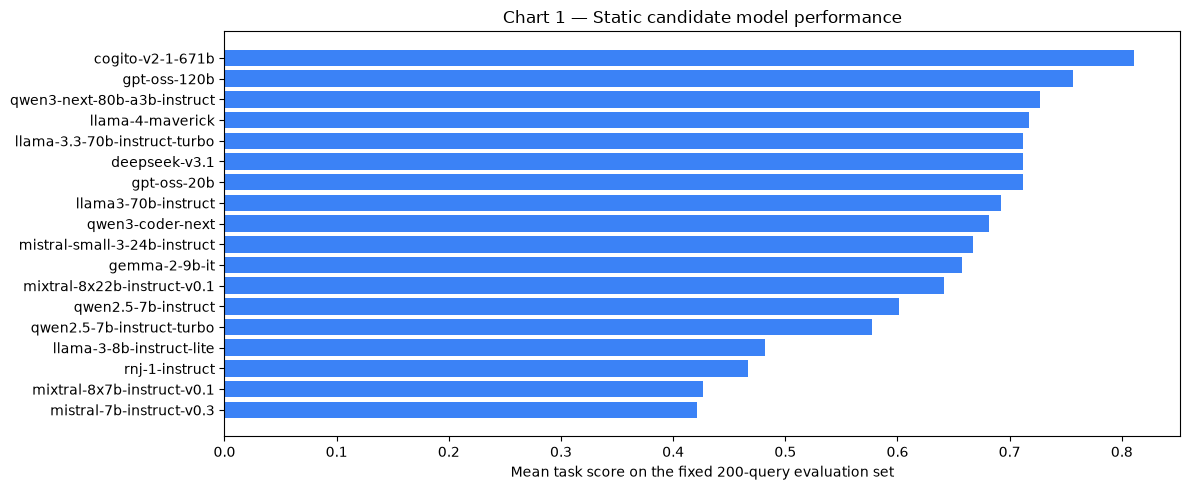

In [2]:
plt.figure(figsize=(12, 5))
by_acc = agg.sort_values("accuracy").reset_index(drop=True)
plt.barh(by_acc["model_name"], by_acc["accuracy"], color="#3b82f6")
plt.xlabel(f"Mean task score on the fixed {len(eval_records):,}-query evaluation set")
plt.title("Chart 1 — Static candidate model performance")
plt.tight_layout()
plt.show()

## Chart 2 — Model vs Cost

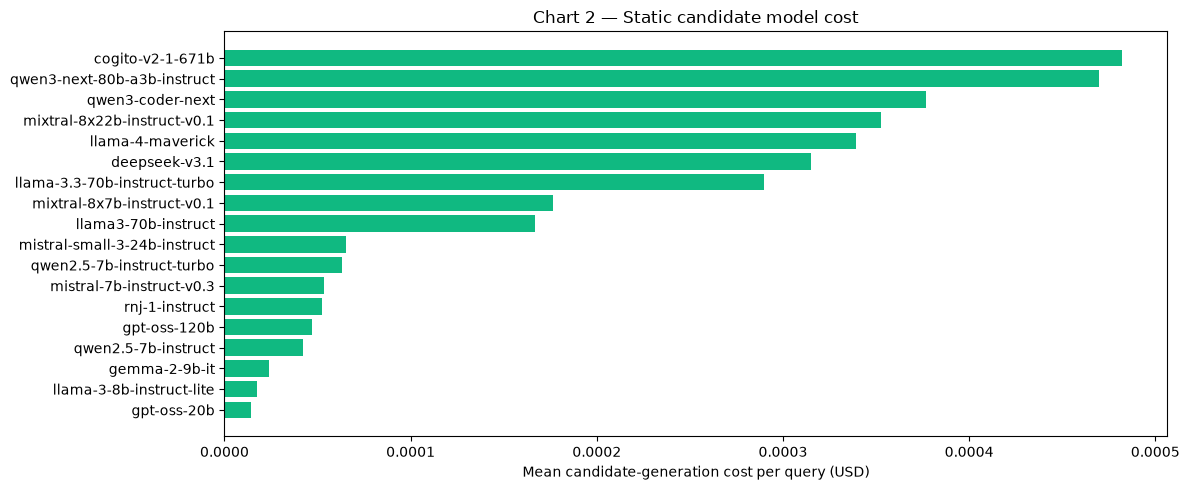

In [3]:
plt.figure(figsize=(12, 5))
by_cost = agg.sort_values("mean_cost").reset_index(drop=True)
plt.barh(by_cost["model_name"], by_cost["mean_cost"], color="#10b981")
plt.xlabel("Mean candidate-generation cost per query (USD)")
plt.title("Chart 2 — Static candidate model cost")
plt.tight_layout()
plt.show()

## Chart 3 — Business case: cost vs accuracy tradeoff

A model is on the **static-model Pareto frontier** when no cheaper static
model has equal or better mean task score. Median-based quadrants are not a
frontier, so the chart computes and highlights the non-dominated points.
A learned router can move beyond this static frontier by choosing a different
candidate for each query.

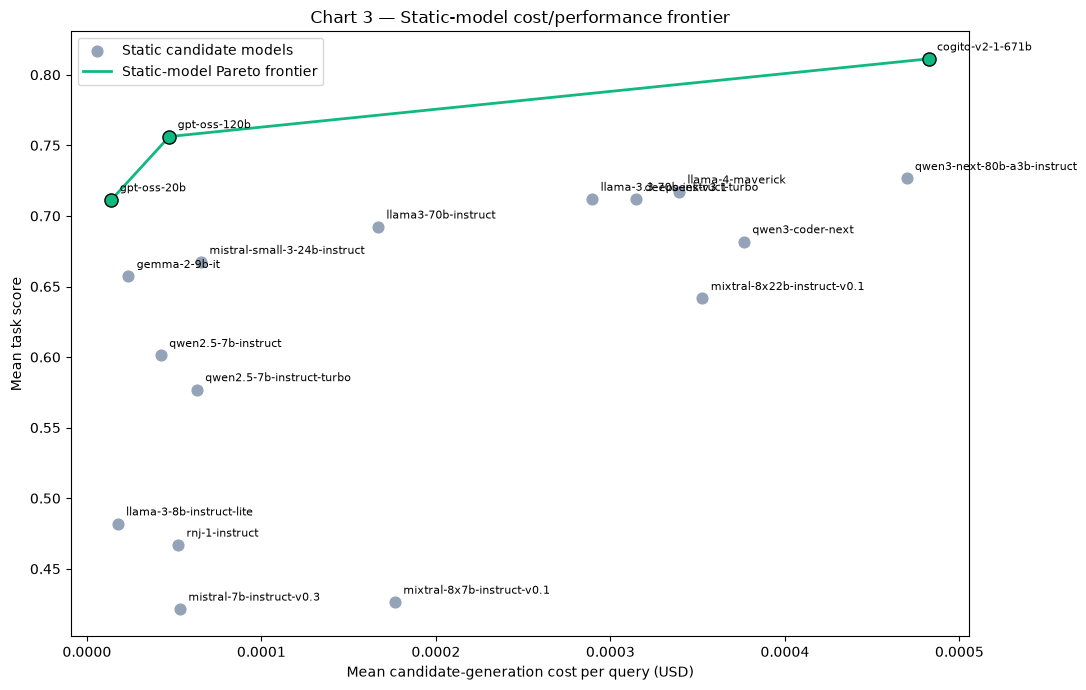

In [4]:
plt.figure(figsize=(11, 7))
plt.scatter(agg["mean_cost"], agg["accuracy"], s=60, color="#94a3b8", label="Static candidate models")
for _, r in agg.iterrows():
    plt.annotate(r["model_name"], (r["mean_cost"], r["accuracy"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.plot(pareto["mean_cost"], pareto["accuracy"], color="#10b981", lw=2, label="Static-model Pareto frontier")
plt.scatter(pareto["mean_cost"], pareto["accuracy"], s=90, color="#10b981", edgecolors="black", zorder=4)
plt.xlabel("Mean candidate-generation cost per query (USD)")
plt.ylabel("Mean task score")
plt.title("Chart 3 — Static-model cost/performance frontier")
plt.legend()
plt.tight_layout()
plt.show()


## Router policies vs the counterfactual oracle

We load each released System-1 router and evaluate it on `eval_records`, the
same fixed held-out queries used for every static-model point above. Add the
downloaded 9B and 27B release paths to `RUN_SPECS` when those runs finish.
Metrics:
- **oracle_acc** — exact match with the oracle's cheapest-acceptable target.
- **acceptable_hit** — our pick lands within the ε-acceptable set.
- **realized cost / performance** — mean per-query US$ and task score actually
  delivered, vs what the oracle policy's picks would have delivered.

The current 0.8B result is explicitly labeled a **1,200-query pilot**. For
the final full-data comparison, set `EVAL_SCOPE = "full_test"` and evaluate
the larger releases on H200 rather than expecting them to fit locally. A fair
9B-vs-27B backbone comparison requires both runs to use the same full training
set, fixed evaluation records, seed/sampling policy, steps or epochs, LoRA/head
configuration, oracle ε, candidate pool, and pricing snapshot.

In [5]:

import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
sys.path.insert(0, str(ROOT))

# Add downloaded full-data releases here when available. Keep the training
# regime in each label so pilot and full-data runs are never conflated.
# Large releases should be evaluated on H200; their returned summary dicts can
# be pasted into PRECOMPUTED_RESULTS to render the comparison locally.
PRECOMPUTED_RESULTS = {
    # "Qwen3.5-9B (full train)": { ...router_vs_gt summary... },
    # "Qwen3.5-27B (full train)": { ...router_vs_gt summary... },
}

RUN_SPECS = {
    "Qwen3.5-0.8B pilot (1.2k train)": ROOT / "training/router_releases/router_8ac97088cc",
    # "Qwen3.5-9B (full train)": ROOT / "downloaded_release/router_<9b_uuid>",
    # "Qwen3.5-27B (full train)": ROOT / "downloaded_release/router_<27b_uuid>",
}

run_results = dict(PRECOMPUTED_RESULTS)
for label, release in RUN_SPECS.items():
    if not (release / "manifest.json").exists():
        print(f"SKIP {label}: missing {release}")
        continue
    print(f"loading {label}: {release}")
    run_results[label] = router_vs_gt(release, records=eval_records)

assert run_results, "No router releases were available for evaluation."
gt = next(iter(run_results.values()))  # shared oracle values; retained for concise plotting
comparison = pd.DataFrame([
    {
        "run": label,
        "oracle_acc": result["oracle_acc"],
        "acceptable_hit": result["acceptable_hit"],
        "performance": result["router_realized_perf"],
        "cost_usd": result["router_realized_cost"],
        "eval_queries": result["test_examples"],
    }
    for label, result in run_results.items()
])
assert comparison["eval_queries"].eq(len(eval_records)).all()
display(comparison)
print(f"oracle policy: cost=${gt['oracle_realized_cost']*1e6:.2f}e-6/query  "
      f"performance={gt['oracle_realized_perf']:.3f}")


loading Qwen3.5-0.8B pilot (1.2k train): /home/mr/Desktop/Fireworks/training/router_releases/router_8ac97088cc


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 7052.01it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


,run,oracle_acc,acceptable_hit,performance,cost_usd,eval_queries
0,Qwen3.5-0.8B pilot (1.2k train),0.73,0.795,0.717222,0.000012,200


oracle policy: cost=$28.80e-6/query  performance=0.922



### Chart 4 — Decision fidelity across router runs


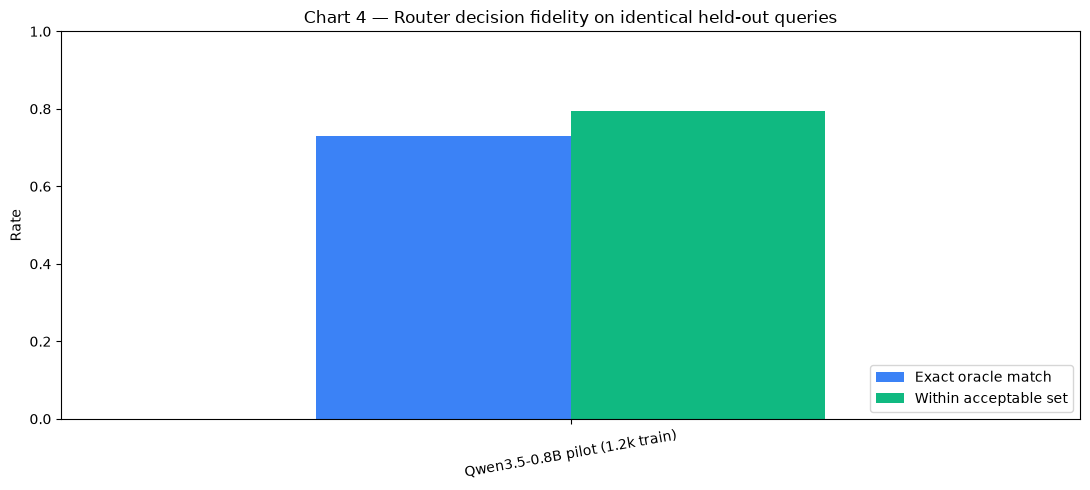

In [6]:

fidelity = (
    comparison.set_index("run")[["oracle_acc", "acceptable_hit"]]
    .rename(columns={"oracle_acc": "Exact oracle match", "acceptable_hit": "Within acceptable set"})
)
ax = fidelity.plot(kind="bar", figsize=(11, 5), color=["#3b82f6", "#10b981"], rot=10)
ax.set_ylim(0, 1)
ax.set_ylabel("Rate")
ax.set_xlabel("")
ax.set_title("Chart 4 — Router decision fidelity on identical held-out queries")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()



### Chart 5 — Realized cost vs performance (router vs oracle)


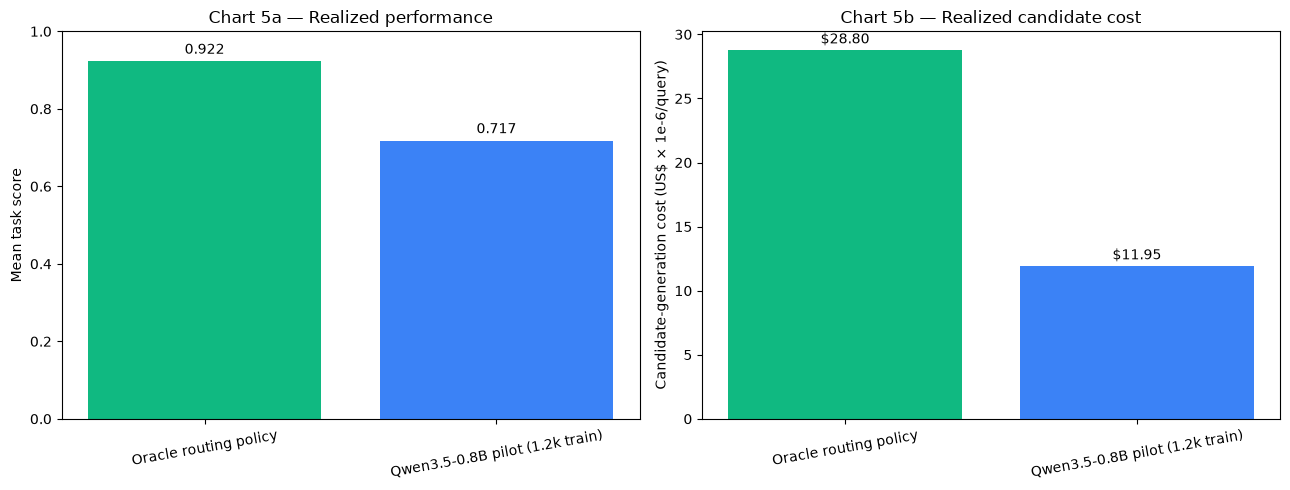

In [7]:

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
methods = ["Oracle routing policy", *comparison["run"]]
perf = [gt["oracle_realized_perf"], *comparison["performance"]]
cost = [gt["oracle_realized_cost"]*1e6, *(comparison["cost_usd"]*1e6)]
colors = ["#10b981", *(["#3b82f6"] * len(comparison))]

ax[0].bar(methods, perf, color=colors)
ax[0].set_ylabel("Mean task score")
ax[0].set_title("Chart 5a — Realized performance")
ax[0].set_ylim(0, 1)
for i, v in enumerate(perf):
    ax[0].text(i, v + 0.02, f"{v:.3f}", ha="center")

ax[1].bar(methods, cost, color=colors)
ax[1].set_ylabel("Candidate-generation cost (US$ × 1e-6/query)")
ax[1].set_title("Chart 5b — Realized candidate cost")
for i, v in enumerate(cost):
    ax[1].text(i, v + 0.5, f"${v:.2f}", ha="center")
for axis in ax:
    axis.tick_params(axis="x", rotation=10)
plt.tight_layout(); plt.show()



### Chart 6 — Router operating points vs the static-model frontier

Every point below uses the same `eval_records`. The oracle is a routing policy,
not a single ground-truth model.

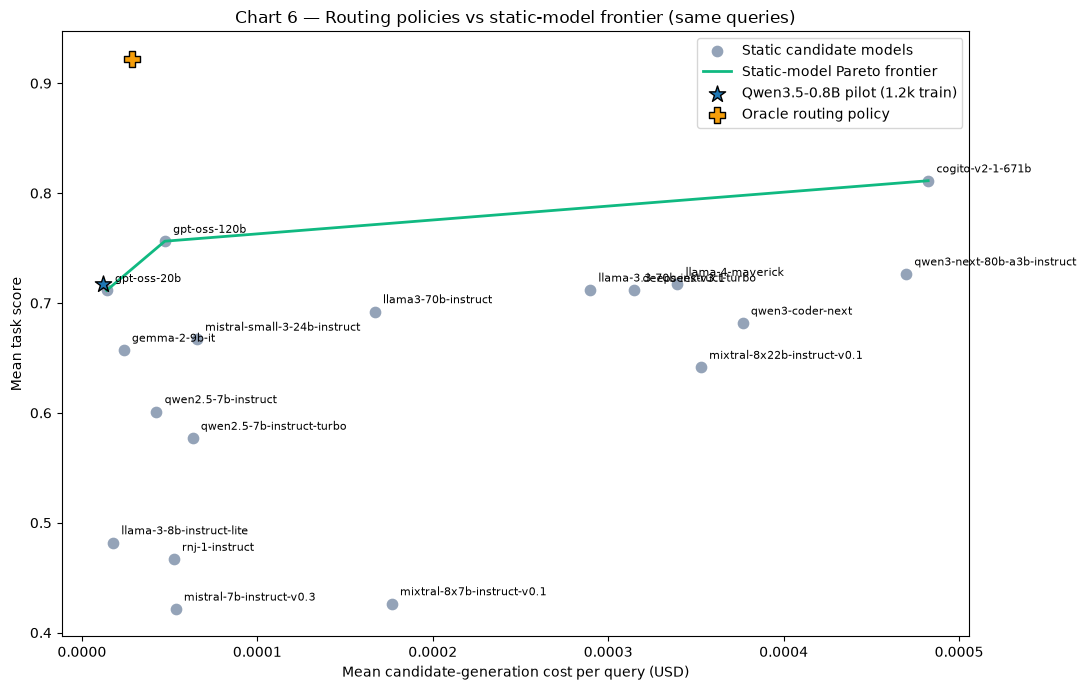

In [8]:

plt.figure(figsize=(11, 7))
plt.scatter(agg["mean_cost"], agg["accuracy"], s=55, color="#94a3b8", label="Static candidate models")
for _, r in agg.iterrows():
    plt.annotate(r["model_name"], (r["mean_cost"], r["accuracy"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.plot(pareto["mean_cost"], pareto["accuracy"], color="#10b981", lw=2, label="Static-model Pareto frontier")
for i, row in comparison.reset_index(drop=True).iterrows():
    plt.scatter([row["cost_usd"]], [row["performance"]], s=150, marker="*",
                edgecolors="black", zorder=5, label=row["run"])
plt.scatter([gt["oracle_realized_cost"]], [gt["oracle_realized_perf"]], s=140,
            marker="P", color="#f59e0b", edgecolors="black", zorder=5, label="Oracle routing policy")
plt.xlabel("Mean candidate-generation cost per query (USD)")
plt.ylabel("Mean task score")
plt.title("Chart 6 — Routing policies vs static-model frontier (same queries)")
plt.legend()
plt.tight_layout(); plt.show()
